In [1]:
import sys, warnings, time
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf
import tensorflow as tf
from tensorflow import keras  # type: ignore
from arch import arch_model
from arch.bootstrap import MCS

TICKERS = ["^GSPC", "^IXIC", "^DJI", "^RUT", "AAPL", "JPM"]   # S&P 500 is the control
START = "2010-01-01"
N_SEEDS = 3      # seeds per neural network; raise to 5 for a final run
LOOK = 22        # days of history the networks see

In [2]:
def load_returns(ticker):
    px = yf.download(ticker, start=START, auto_adjust=True, progress=False)
    if isinstance(px.columns, pd.MultiIndex):
        px.columns = px.columns.get_level_values(0)
    close = px["Close"].dropna()
    r = (100 * np.log(close / close.shift(1))).dropna()
    r.name = "log_return"
    return r

SPECS = {
    "GARCH(1,1)": dict(vol="GARCH", p=1, q=1),
    "EGARCH":     dict(vol="EGARCH", p=1, o=1, q=1),
    "GJR-GARCH":  dict(vol="GARCH", p=1, o=1, q=1),
}

def garch_forecasts(r, split):
    """Parameters estimated on training data only; one-day-ahead forecasts for the test period."""
    gf_all, test = {}, {}
    for name, spec in SPECS.items():
        res = arch_model(r, mean="Constant", dist="t", **spec).fit(last_obs=r.index[split - 1], disp="off")
        gf = res.forecast(horizon=1, start=r.index[0], reindex=False).variance["h.1"]  # made at t, for t+1
        gf_all[name] = gf
        test[name] = gf.shift(1).loc[r.index[split:]]
    test["Rolling 21d var"] = r.rolling(21).var().shift(1).loc[r.index[split:]]
    return gf_all, pd.DataFrame(test)

In [3]:
def qlike_loss(y_true, y_pred):
    y_, base = y_true[:, 0:1], y_true[:, 1:2]
    out = tf.clip_by_value(y_pred, -4.0, 4.0)
    f = base * tf.exp(out)
    return tf.reduce_mean(tf.math.log(f) + y_ / f)

def build_model(n_feat, lr=3e-4):
    m = keras.Sequential([
        keras.layers.Input(shape=(LOOK, n_feat)),
        keras.layers.LSTM(16),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=qlike_loss)
    return m

def train_ensemble(s, n_seeds):
    preds = []
    for seed in range(n_seeds):
        np.random.seed(seed); tf.random.set_seed(seed)
        m = build_model(s["X_tr"].shape[2])
        early = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
        m.fit(s["X_tr"], s["Y_tr"], validation_data=(s["X_val"], s["Y_val"]),
              epochs=200, batch_size=64, callbacks=[early], verbose=0)
        out = np.clip(m.predict(s["X_te"], verbose=0).ravel(), -4, 4)
        preds.append(s["Y_te"][:, 1] * np.exp(out))
    return np.array(preds).mean(axis=0)        # ensemble = average of variance forecasts

def nn_forecasts(r, gjr_gf, split, n_seeds):
    feat = pd.DataFrame({
        "ret": r, "sq_ret": r ** 2,
        "abs_mean_5d": r.abs().rolling(5).mean(),
        "rv_21d": r.rolling(21).std() * np.sqrt(252),
        "log_garch_var": np.log(gjr_gf),
    }).dropna()
    split_date = r.index[split]
    tr = feat.index < split_date
    mu, sd = feat[tr].mean(), feat[tr].std()
    feat_s = ((feat - mu) / sd).clip(-5, 5)
    vals, idx = feat_s.values, feat_s.index
    rsq = (r ** 2).loc[idx].values
    gv = gjr_gf.loc[idx].values

    X, y, g, dates = [], [], [], []
    for t in range(LOOK, len(idx)):
        X.append(vals[t - LOOK:t]); y.append(rsq[t]); g.append(gv[t - 1]); dates.append(idx[t])
    X, y, g, dates = np.array(X), np.array(y), np.array(g), pd.DatetimeIndex(dates)
    train_mask = dates < split_date
    const_var = (r ** 2)[r.index < split_date].mean()

    def make_sets(X_, base):
        Y = np.column_stack([y, base])
        Xa, Ya = X_[train_mask], Y[train_mask]
        v = int(len(Xa) * 0.9)
        return dict(X_tr=Xa[:v], Y_tr=Ya[:v], X_val=Xa[v:], Y_val=Ya[v:],
                    X_te=X_[~train_mask], Y_te=Y[~train_mask])

    test_dates = dates[~train_mask]
    out = pd.DataFrame(index=test_dates)
    out["Hybrid"] = train_ensemble(make_sets(X, g), n_seeds)
    out["LSTM"] = train_ensemble(make_sets(X[:, :, :4], np.full(len(y), const_var)), n_seeds)
    return out

In [4]:
def dm_test(proxy, fa, fb, lags=5):
    fa, fb = fa.clip(lower=1e-8), fb.clip(lower=1e-8)
    d = ((np.log(fa) + proxy / fa) - (np.log(fb) + proxy / fb)).values
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.tvalues[0], res.pvalues[0]

def run_ticker(ticker):
    r = load_returns(ticker)
    split = int(len(r) * 0.8)
    gf_all, fc = garch_forecasts(r, split)
    nn = nn_forecasts(r, gf_all["GJR-GARCH"], split, N_SEEDS)
    fc = fc.join(nn, how="inner").dropna().clip(lower=1e-8)
    proxy = r.loc[fc.index] ** 2
    losses = fc.apply(lambda f: np.log(f) + proxy / f)
    dm_h, p_h = dm_test(proxy, fc["Hybrid"], fc["GJR-GARCH"])
    dm_l, p_l = dm_test(proxy, fc["LSTM"], fc["GJR-GARCH"])
    try:
        mcs = MCS(losses, size=0.10, reps=1000, seed=42)
        mcs.compute()
        included = list(mcs.included)
    except Exception as e:
        included = [f"MCS failed: {e}"]
    return dict(ticker=ticker, n_test=len(fc), start=fc.index[0].date(), end=fc.index[-1].date(),
                qlike=losses.mean(), dm_hybrid_vs_gjr=(dm_h, p_h), dm_lstm_vs_gjr=(dm_l, p_l),
                mcs=included)

In [5]:
results = {}
for tk in TICKERS:
    t0 = time.time()
    try:
        results[tk] = run_ticker(tk)
        print(f"{tk}: done in {time.time() - t0:.0f}s")
    except Exception as e:
        print(f"{tk}: FAILED - {e}")

^GSPC: done in 54s
^IXIC: done in 38s
^DJI: done in 32s
^RUT: done in 33s
AAPL: done in 47s
JPM: done in 57s


In [6]:
rows = []
for tk, res in results.items():
    q = res["qlike"]
    rows.append({
        "ticker": tk, "test days": res["n_test"],
        "GARCH(1,1)": q["GARCH(1,1)"], "EGARCH": q["EGARCH"], "GJR-GARCH": q["GJR-GARCH"],
        "Rolling var": q["Rolling 21d var"], "LSTM": q["LSTM"], "Hybrid": q["Hybrid"],
        "Hybrid vs GJR (%)": 100 * (q["Hybrid"] - q["GJR-GARCH"]) / abs(q["GJR-GARCH"]),
        "DM p (hybrid vs GJR)": res["dm_hybrid_vs_gjr"][1],
        "DM p (LSTM vs GJR)": res["dm_lstm_vs_gjr"][1],
        "90% MCS": ", ".join(res["mcs"]),
    })
summary = pd.DataFrame(rows).set_index("ticker")
display(summary.round(4))
summary.to_csv("../data/replication_summary.csv")

n = len(summary)
print(f"\nHybrid has lower QLIKE than GJR-GARCH in {(summary['Hybrid vs GJR (%)'] < 0).sum()} of {n} assets")
print(f"...and the difference is significant (p<0.05) in {(summary['DM p (hybrid vs GJR)'] < 0.05).sum()} of {n}")
print(f"EGARCH beats GARCH(1,1) in {(summary['EGARCH'] < summary['GARCH(1,1)']).sum()} of {n}; "
      f"GJR-GARCH beats GARCH(1,1) in {(summary['GJR-GARCH'] < summary['GARCH(1,1)']).sum()} of {n}")

,test days,"GARCH(1,1)",EGARCH,GJR-GARCH,Rolling var,LSTM,Hybrid,Hybrid vs GJR (%),DM p (hybrid vs GJR),DM p (LSTM vs GJR),90% MCS
ticker,,,,,,,,,,,
^GSPC,845,0.6408,0.5882,0.5829,0.7476,0.5624,0.5623,-3.5273,0.0519,0.5246,"EGARCH, Hybrid, LSTM"
^IXIC,845,1.3214,1.2986,1.2972,1.3915,1.2626,1.2960,-0.0945,0.0114,0.1384,"EGARCH, Hybrid, LSTM"
^DJI,845,0.5008,0.4853,0.4742,0.5721,0.4897,0.4708,-0.7017,0.0094,0.6945,"EGARCH, GARCH(1,1), Hybrid, LSTM"
^RUT,845,1.4905,1.4952,1.5075,1.5317,1.4764,1.5074,-0.0064,0.9861,0.3064,"EGARCH, GARCH(1,1), GJR-GARCH, Hybrid, LSTM"
AAPL,845,1.8692,1.8419,1.8509,2.0047,1.8682,1.8495,-0.0779,0.3543,0.4519,"EGARCH, GARCH(1,1), GJR-GARCH, Hybrid, LSTM"
JPM,845,1.6747,1.6530,1.6730,1.7697,1.6438,1.6607,-0.7355,0.1527,0.1286,"EGARCH, GARCH(1,1), GJR-GARCH, Hybrid, LSTM"



Hybrid has lower QLIKE than GJR-GARCH in 6 of 6 assets
...and the difference is significant (p<0.05) in 2 of 6
EGARCH beats GARCH(1,1) in 5 of 6; GJR-GARCH beats GARCH(1,1) in 5 of 6


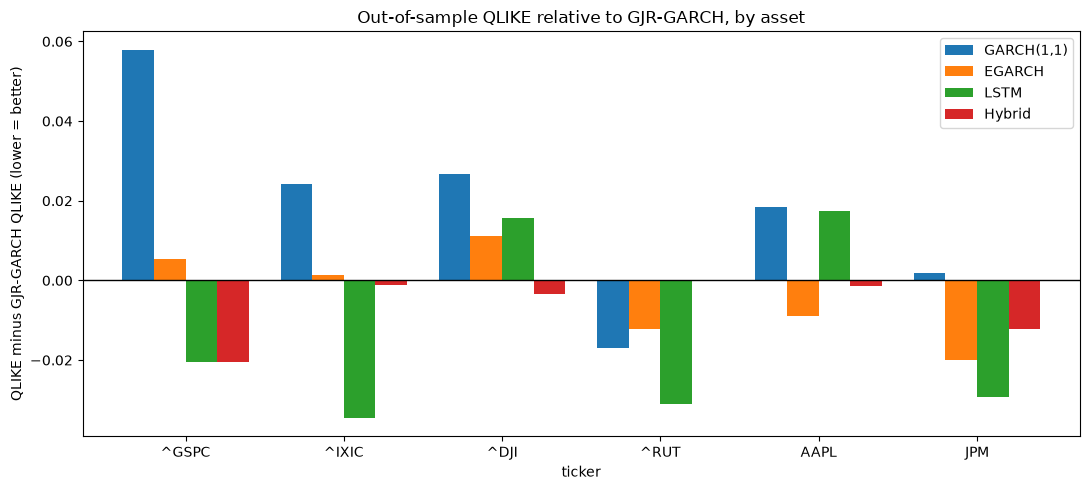

In [7]:
models = ["GARCH(1,1)", "EGARCH", "LSTM", "Hybrid"]
rel = summary[models].sub(summary["GJR-GARCH"], axis=0)    # negative = better than GJR-GARCH
ax = rel.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("QLIKE minus GJR-GARCH QLIKE (lower = better)")
ax.set_title("Out-of-sample QLIKE relative to GJR-GARCH, by asset")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()